## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_u_v_point_obs, get_wl_point_obs
from helper import plot_shred_reconstruction

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.tshred.TSHRED import TSHRED
from src.shred.SHRED import SHRED
from src.train import fit, evaluate

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

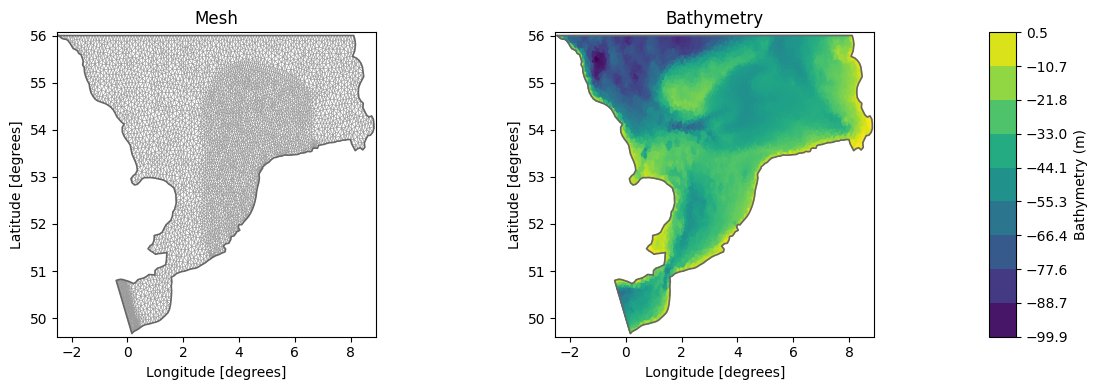

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

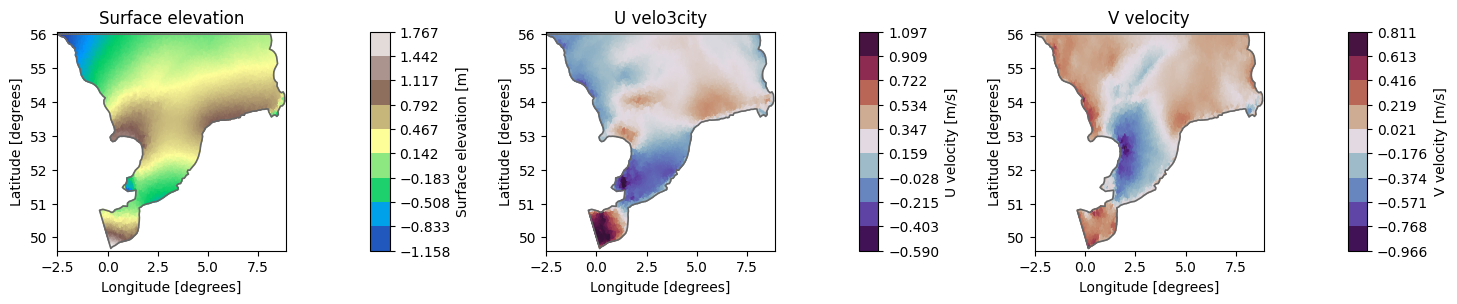

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


<Axes: >

<Axes: >

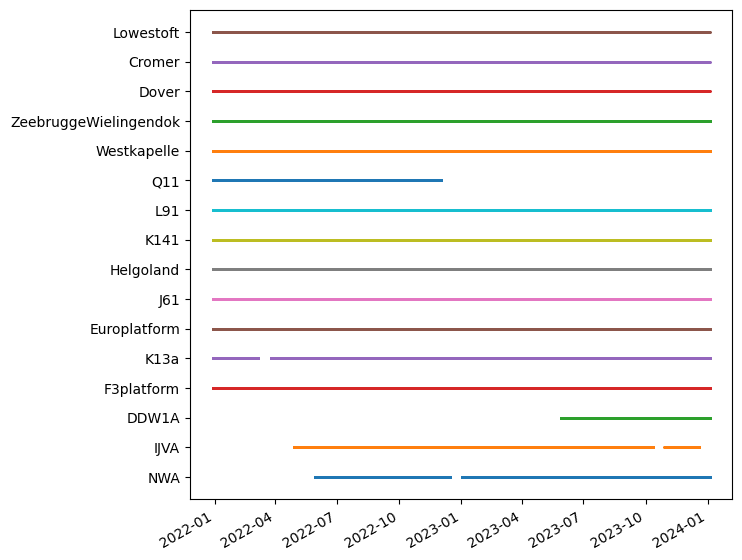

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist)

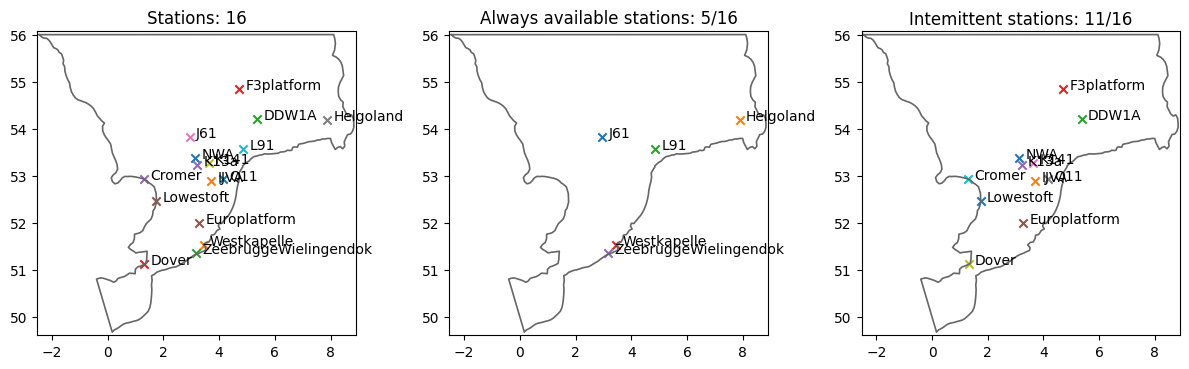

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

# free memory
del stn_data

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 16])


## Idea 0: Only Available Sensors

In [10]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

#counts nans
nan_counts_available = np.isnan(measurements_av.numpy()).sum(axis=0)
nan_counts_intermittent = np.isnan(measurements[:, [stations.index(s) for s in intermittent]].numpy()).sum(axis=0)

#available stations
print("Available stations:\n", [f"{s.name}: {nan_counts_available[i]}" for i, s in enumerate(availables)])
print("Intermittent stations:\n", [f"{s.name}: {nan_counts_intermittent[i]}" for i, s in enumerate(intermittent)])

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)

Available stations:
 ['J61: 0', 'Helgoland: 0', 'L91: 0', 'Westkapelle: 0', 'ZeebruggeWielingendok: 0']
Intermittent stations:
 ['NWA: 8570', 'IJVA: 8296', 'DDW1A: 25127', 'F3platform: 18', 'K13a: 1151', 'Europlatform: 435', 'K141: 67', 'Q11: 19139', 'Dover: 18015', 'Cromer: 18320', 'Lowestoft: 18051']

After selecting always-available stations only:
H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 5])


In [11]:
# Data manager

lags = 48
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 100, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = 100)
manager.add_data(V, id = "V velocity", compress = 100)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Data shapes after preparation:
Train:	 torch.Size([28031, 48, 5]) -> torch.Size([28031, 300])
Val:	 torch.Size([3504, 48, 5]) -> torch.Size([3504, 300])
Test:	 torch.Size([3504, 48, 5]) -> torch.Size([3504, 300])

Input shape for the model: 5
Output shape for the model: 300


Starting training...


Training:  15%|█▌        | 30/200 [04:44<26:54,  9.50s/it, Train Loss=0.0065, Val Loss=0.0064, Patience=19, Best Val Loss=0.0062]

Starting training...


Training:  15%|█▌        | 30/200 [04:44<26:54,  9.50s/it, Train Loss=0.0065, Val Loss=0.0064, Patience=19, Best Val Loss=0.0062]

Early stopping at epoch 31
Training completed with best validation loss: 0.0062


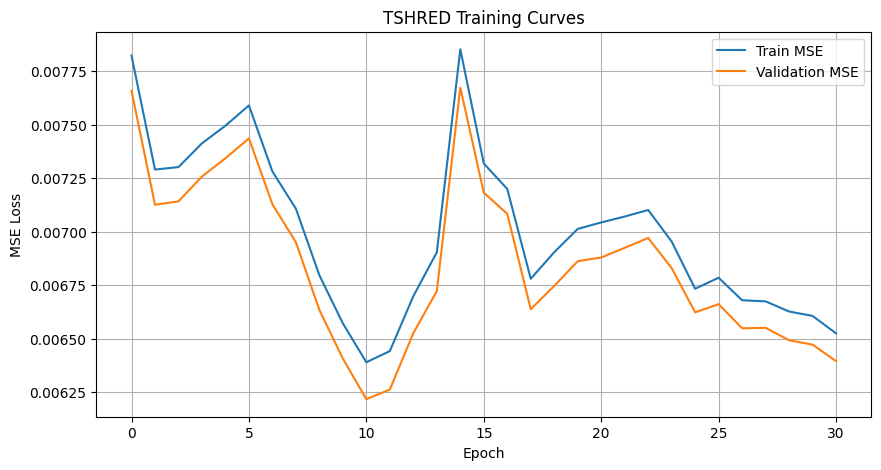

Starting training...


Training:  15%|█▌        | 30/200 [04:44<26:54,  9.50s/it, Train Loss=0.0065, Val Loss=0.0064, Patience=19, Best Val Loss=0.0062]

Early stopping at epoch 31
Training completed with best validation loss: 0.0062


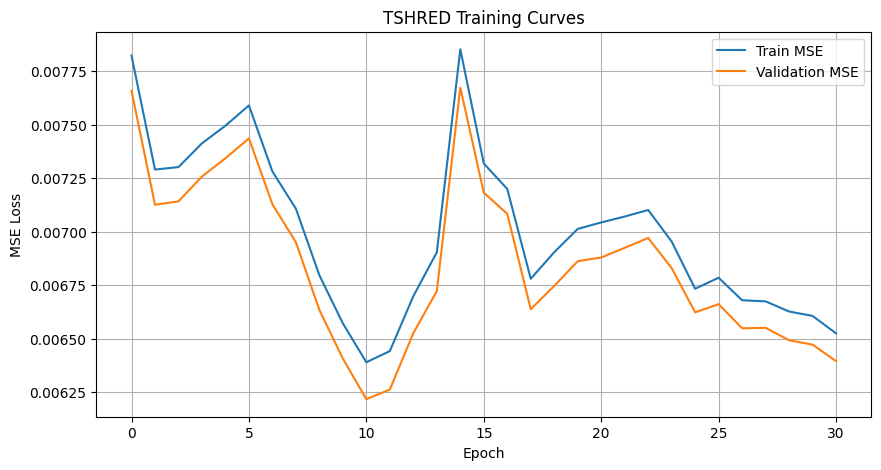

Train MSE: 0.007
Val   MSE: 0.006
Test  MSE: 0.012


In [12]:
# TSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="vanilla_transformer",
    encoder_depth=1,
    d_model=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_depth=2,
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    device=device,
 )

tshred = TSHRED(args=model_args).to(device)
train_errors, valid_errors = fit(tshred, train_dataset, val_dataset, patience=40)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('TSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# Mean squared errors
train_mse = evaluate(tshred, train_dataset)
val_mse = evaluate(tshred, val_dataset)
test_mse = evaluate(tshred, test_dataset)

print(f"Train MSE: {train_mse:.3f}")
print(f"Val   MSE: {val_mse:.3f}")
print(f"Test  MSE: {test_mse:.3f}")

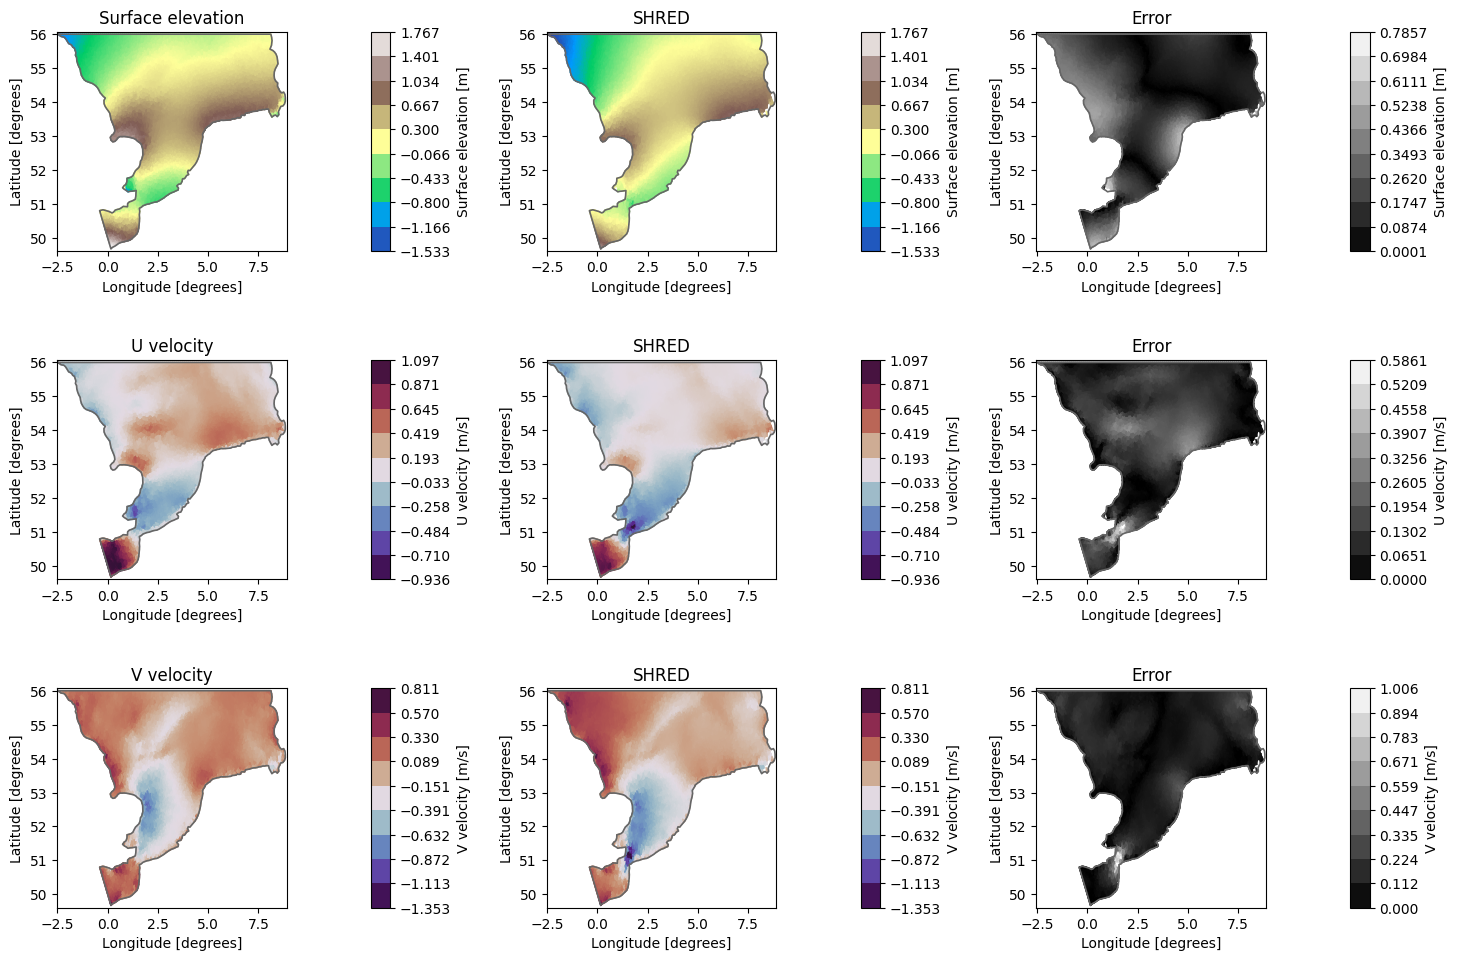

In [13]:
# SHRED RECONSTRUCTION
engine = SHREDEngine(manager, tshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom)